In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator

plt.rcParams.update({
    'font.size': 14,        # Default text size
    'axes.titlesize': 18,   # Title size
    'axes.labelsize': 16,   # X and Y axis label size
    'xtick.labelsize': 14,  # X tick label size
    'ytick.labelsize': 14,  # Y tick label size
    'legend.fontsize': 14,  # Legend font size
    'figure.titlesize': 20  # Figure-level title size
})


In [43]:
B1 = pd.read_csv('../data/groundwater/Temp/BA0000007FD53E41_092826200001_1.csv', skiprows=24, on_bad_lines='skip', sep=';')
B2 = pd.read_csv('../data/groundwater/Temp/AE000000824F6A41_092826200001_1.csv', skiprows=24, on_bad_lines='skip', sep=';')
B3 = pd.read_csv('../data/groundwater/Temp/23000000824F2141_092826200001_1.csv', skiprows=24, on_bad_lines='skip', sep=';')
A = pd.read_csv('../data/groundwater/Temp/9600000082456D41_092926005501_1.csv', skiprows=24, on_bad_lines='skip', sep=';')

start = pd.Timestamp('2026-09-28 19:55:01')
end = pd.Timestamp('2026-10-01 09:00:01')

B1_time = pd.to_datetime(B1['Date'] + ' ' + B1['Time'])
B2_time = pd.to_datetime(B2['Date'] + ' ' + B2['Time'])
B3_time = pd.to_datetime(B3['Date'] + ' ' + B3['Time'])
A_time = pd.to_datetime(A['Date'] + ' ' + A['Time'])

B1 = B1.loc[(B1_time >= start) & (B1_time <= end)]
B2 = B2.loc[(B2_time >= start) & (B2_time <= end)]
B3 = B3.loc[(B3_time >= start) & (B3_time <= end)]
A = A.loc[(A_time >= start) & (A_time <= end)]


In [44]:
tides = pd.read_csv('../data/water_levels/QUINTA_tides_2030.csv')
tides['dates'] = pd.to_datetime(tides['dates'], utc=True)

tides['dates'] = tides['dates'].dt.tz_localize(None)
tides_window = tides[(tides['dates'] >= start) & (tides['dates'] <= end)]

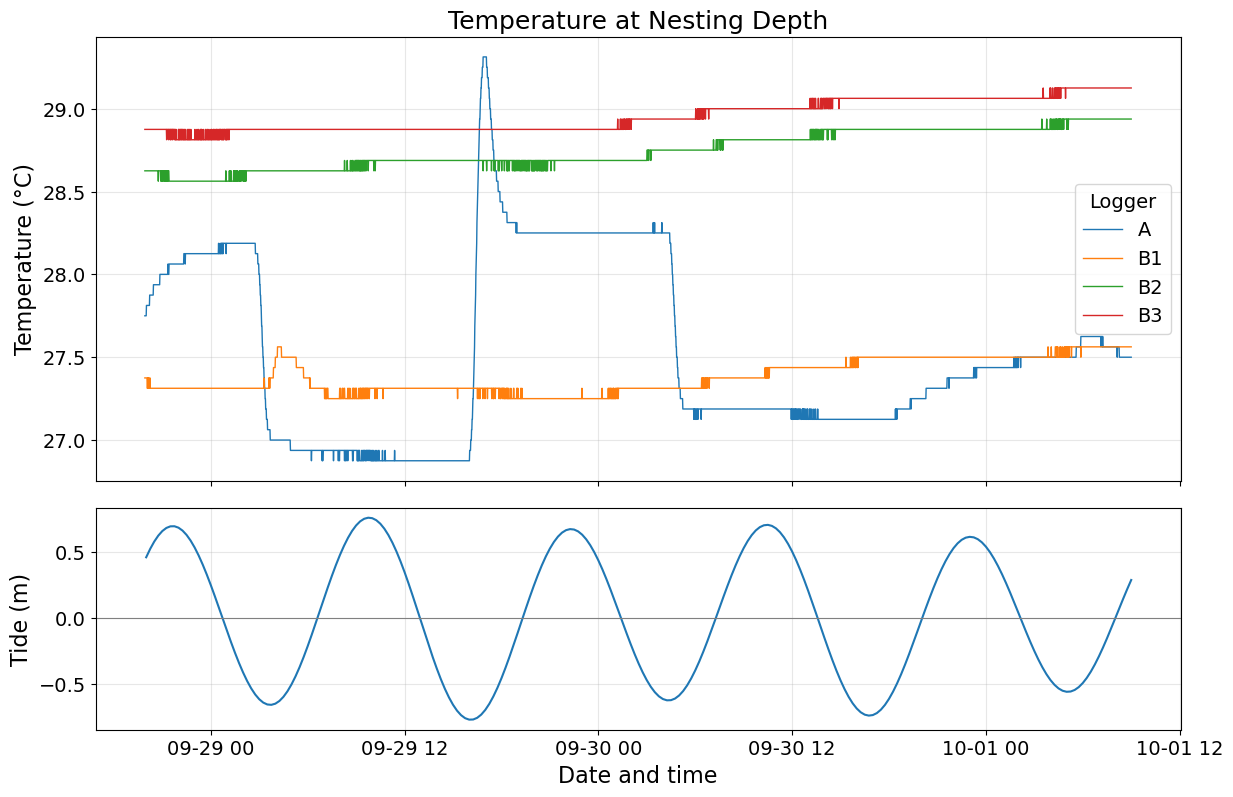

In [45]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={'height_ratios': [3, 1.5], 'hspace': 0.08})

for name, data in {'A': A, 'B1': B1, 'B2': B2, 'B3': B3}.items():
    datetime = pd.to_datetime(data['Date'] + ' ' + data['Time'])
    temperature = pd.to_numeric(data['Value'], errors='coerce')
    ax1.plot(datetime, temperature, linewidth=1, label=name)

ax1.set_title('Temperature at Nesting Depth')
ax1.set_ylabel('Temperature (°C)')
ax1.grid(alpha=0.3)
ax1.legend(title='Logger')

ax2.plot(tides_window['dates'], tides_window['tide'], linewidth=1.5)
ax2.axhline(0, color='gray', linewidth=0.8)
ax2.set_ylabel('Tide (m)')
ax2.set_xlabel('Date and time')
ax2.grid(alpha=0.3)

### Comparison to TD-diver Temperature

In [46]:
folder = Path("../data/groundwater/DiverCSV")

dfs = []

for file in folder.glob("*.CSV"):
    if file.stem.startswith(("A1_", "A2_", "B1_", "B2_", "B3_")):
        df = pd.read_csv(file, skiprows=51, sep=",", encoding="cp1252")

        df['diver'] = file.stem.split("_")[0]
        dfs.append(df)

all_divers = pd.concat(dfs, ignore_index=True)

A1_diver = all_divers[all_divers['diver'] == 'A1'].drop(columns=['Pressure[cmH2O]', 'diver']).rename(columns={'Temperature[°C]':'Temperature'})[:-1]
A2_diver = all_divers[all_divers['diver'] == 'A2'].drop(columns=['Pressure[cmH2O]', 'diver']).rename(columns={'Temperature[°C]':'Temperature'})[:-1]
B1_diver = all_divers[all_divers['diver'] == 'B1'].drop(columns=['Pressure[cmH2O]', 'diver']).rename(columns={'Temperature[°C]':'Temperature'})[:-1]
B2_diver = all_divers[all_divers['diver'] == 'B2'].drop(columns=['Pressure[cmH2O]', 'diver']).rename(columns={'Temperature[°C]':'Temperature'})[:-1]
B3_diver = all_divers[all_divers['diver'] == 'B3'].drop(columns=['Pressure[cmH2O]', 'diver']).rename(columns={'Temperature[°C]':'Temperature'})[:-1]

(np.float64(20724.829872685186), np.float64(20727.375011574073))

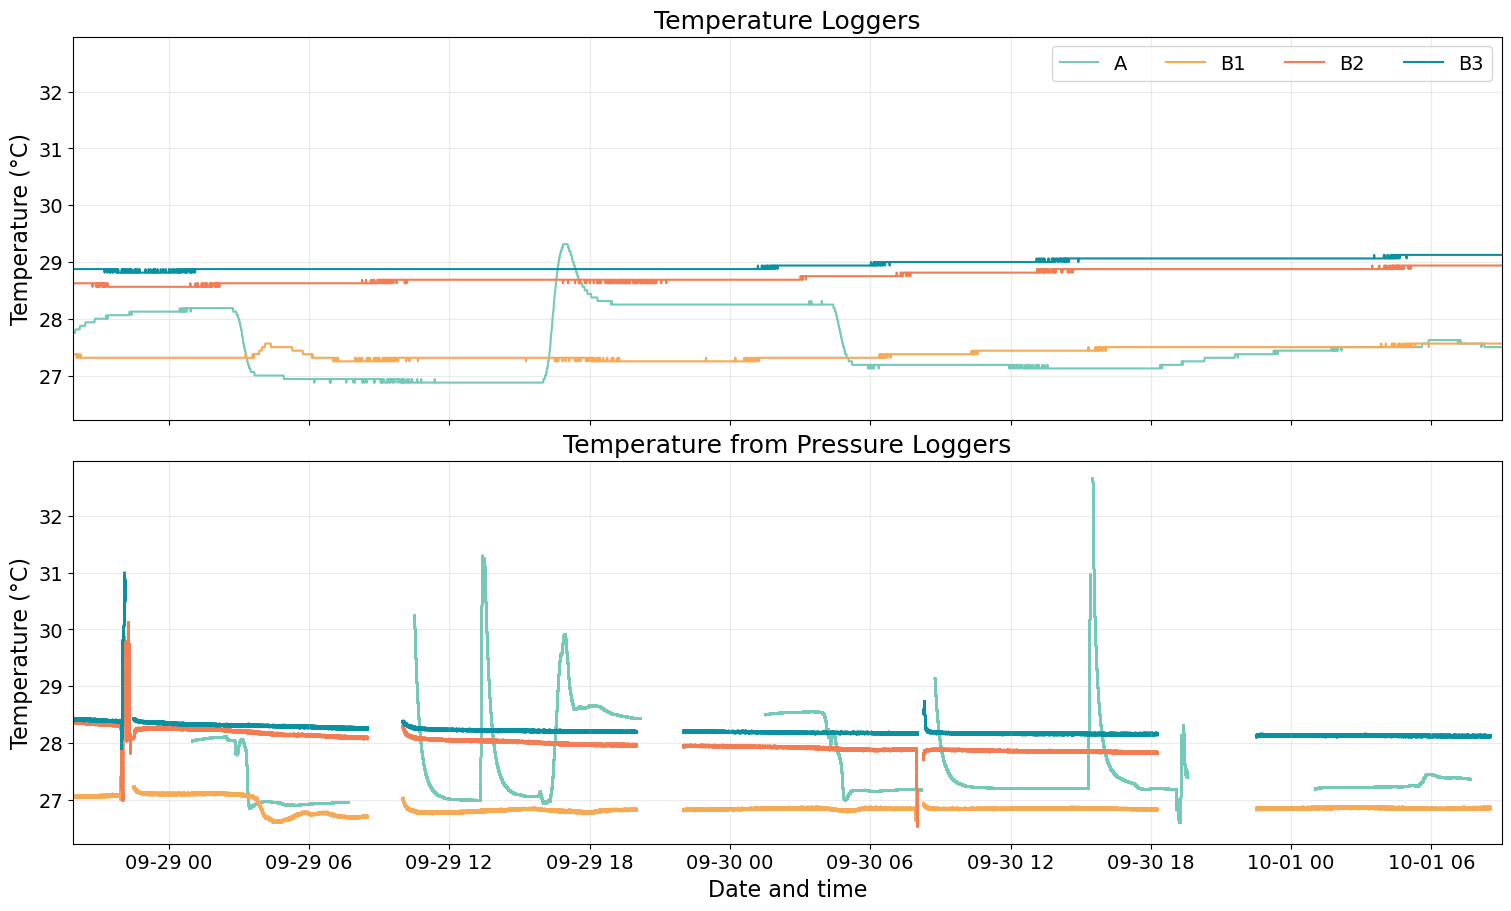

In [47]:
temperature_loggers = {'A': A, 'B1': B1, 'B2': B2, 'B3': B3}
pressure_loggers = {'A1': A1_diver, 'B1': B1_diver, 'B2': B2_diver, 'B3': B3_diver}

colors = {"A": "#74c9b9", "A1": "#74c9b9", "B1": "#f8a953", "B2": "#f47c53", "B3": "#0a91a1"}

for df in temperature_loggers.values():
    df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], errors="coerce")
    df["Value"] = pd.to_numeric(df["Value"], errors="coerce")


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), sharex=True, gridspec_kw={"height_ratios": [1, 1]}, constrained_layout=True)

all_temperatures = []

for name, df in temperature_loggers.items():
    values = df["Value"].dropna()
    all_temperatures.extend(values)

    ax1.plot(df["datetime"], df["Value"], color=colors[name], linewidth=1.5, label=name)

for name, df in pressure_loggers.items():
    df["datetime"] = pd.to_datetime(df["Date/time"], errors="coerce")
    df["Temperature"] = pd.to_numeric(df["Temperature"], errors="coerce")
    df = df[ (df["datetime"] >= start) & (df["datetime"] <= end)]
    all_temperatures.extend(df["Temperature"].dropna())

    ax2.scatter(df["datetime"], df["Temperature"], color=colors[name], s=0.5, label=name)

y_min = min(all_temperatures)
y_max = max(all_temperatures)
padding = 0.05 * (y_max - y_min)

ax1.set_ylim(y_min - padding, y_max + padding)
ax2.set_ylim(y_min - padding, y_max + padding)

ax1.set_title("Temperature Loggers")
ax1.set_ylabel("Temperature (°C)")
ax1.legend(ncol=4)
ax1.grid(alpha=0.25)

ax2.set_title("Temperature from Pressure Loggers")
ax2.set_ylabel("Temperature (°C)")
ax2.set_xlabel("Date and time")
ax2.grid(alpha=0.25)

ax2.set_xlim(start, end)



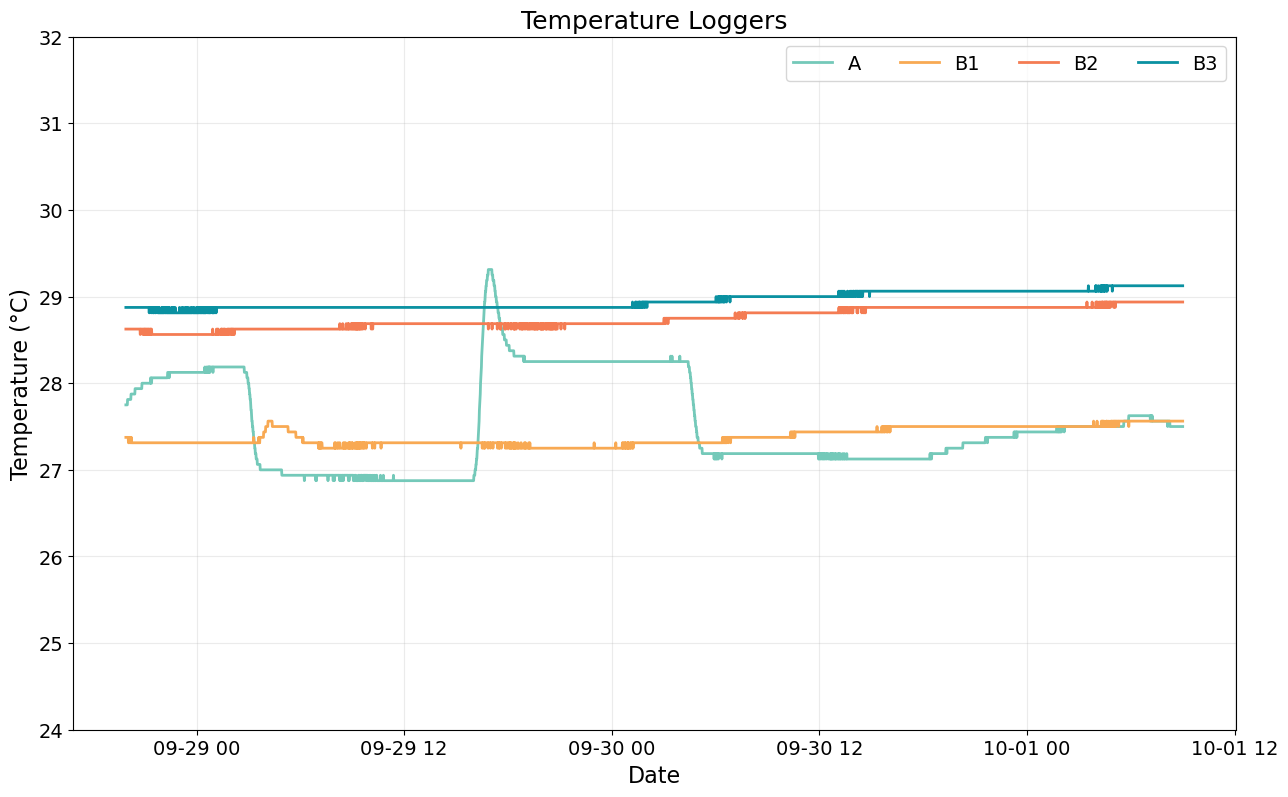

In [48]:
temperature_loggers = {'A': A, 'B1': B1, 'B2': B2, 'B3': B3}
colors = {"A": "#74c9b9", "B1": "#f8a953", "B2": "#f47c53", "B3": "#0a91a1"}

for df in temperature_loggers.values():
    df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], errors="coerce")
    df["Value"] = pd.to_numeric(df["Value"], errors="coerce")

plt.figure(figsize=(15, 9))

all_temperatures = []

for name, df in temperature_loggers.items():
    values = df["Value"].dropna()
    all_temperatures.extend(values)

    plt.plot(df["datetime"], df["Value"], color=colors[name], linewidth=2, label=name)

plt.ylim(24, 32)
plt.title("Temperature Loggers")
plt.xlabel('Date')
plt.ylabel("Temperature (°C)")
plt.legend(ncol=4)
plt.grid(alpha=0.25)